# Project Topic

Landslide Susceptibility Prediction

# Project Description

The project focuses on developing a machine learning-based system to predict landslide susceptibility by analyzing various geo-environmental factors. The primary objective is to identify areas that are more likely to experience landslides based on geographical and environmental characteristics.

The project uses a dataset containing environmental parameters such as elevation, slope, rainfall, aspect, distance from rivers, flow accumulation, Normalized Difference Vegetation Index (NDVI), and Land Use/Land Cover (LULC). These features are used to identify patterns and relationships associated with landslide occurrences.

The implementation involves several stages, including data exploration, statistical analysis, feature selection, and model development. A Random Forest Classifier is used as the  prediction algorithm to classify locations into two categories: landslide (1) and non-landslide (0).

To improve model performance, GridSearchCV  is implemented for hyperparameter tuning, using the F1-score as the optimization metric. Model performance is evaluated using accuracy, precision, recall, F1-score, confusion matrix, ROC-AUC, and PR-AUC.

Additionally, feature importance, permutation importance, and SHAP (SHapley Additive exPlanations) are implemented to understand the contribution of individual environmental factors to the model's predictions and improve model interpretability.

The trained model and selected feature information are saved using Joblib for subsequent use in the prediction application.

Key Technologies and Techniques:
- Python, Pandas, NumPy
- Data Exploration and Statistical Analysis
- Geo-environmental Feature Analysis
- Random Forest Classification
- GridSearchCV 
- Model Evaluation and Performance Metrics
- Feature Importance and Permutation Importance
- SHAP-based Model Explainability
- Model Serialization using Joblib

In [ ]:

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report


df = pd.read_csv("landslide_modelling_dataset_12409.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (12409, 30)


,sample_id,gee_system_index,longitude,latitude,class,Aspect_z,Dist_River_z,Elevation_z,FlowAccumulation_z,NDVI_z,...,LULC_60,LULC_70,LULC_80,LULC_90,LULC_100,lulc_code,lulc_name,nearest_inventory_sno,match_dist_m,n_samples_at_coord
0,1,00000000000000001f6f_0,76.077524,30.960885,0,-1.196783,-0.115485,-1.214145,-0.388618,-0.218111,...,0,0,0,0,0,40,Cropland,NaN,NaN,1
1,2,00000000000000002496_0,76.076176,30.984061,0,-1.055014,-0.127904,-1.213353,-0.578275,-0.783018,...,0,0,0,0,0,40,Cropland,NaN,NaN,1
2,3,00000000000000001df2_0,76.073481,30.967891,0,-1.308173,-0.119583,-1.212562,-0.578275,-0.288624,...,0,0,0,0,0,40,Cropland,NaN,NaN,1
3,4,000000000000000030af_0,76.232483,31.000500,0,0.585456,-0.127251,-1.212562,0.422743,-0.399849,...,0,0,0,0,0,40,Cropland,NaN,NaN,1
4,5,00000000000000001e24_0,75.987512,31.237656,0,-0.477812,-0.130197,-1.211770,2.962928,-0.164858,...,0,0,0,0,0,40,Cropland,NaN,NaN,1


In [ ]:

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df["class"].value_counts())

print("\nClass Percentage:")
print(df["class"].value_counts(normalize=True) * 100)


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 12409 entries, 0 to 12408
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   sample_id              12409 non-null  int64  
 1   gee_system_index       12409 non-null  str    
 2   longitude              12409 non-null  float64
 3   latitude               12409 non-null  float64
 4   class                  12409 non-null  int64  
 5   Aspect_z               12409 non-null  float64
 6   Dist_River_z           12409 non-null  float64
 7   Elevation_z            12409 non-null  float64
 8   FlowAccumulation_z     12409 non-null  float64
 9   NDVI_z                 12409 non-null  float64
 10  Rainfall_z             12409 non-null  float64
 11  Slope_z                12409 non-null  float64
 12  aspect_deg             12409 non-null  float64
 13  elevation_m            12409 non-null  int64  
 14  slope_deg              12409 non-null  float

,sample_id,longitude,latitude,class,Aspect_z,Dist_River_z,Elevation_z,FlowAccumulation_z,NDVI_z,Rainfall_z,...,LULC_50,LULC_60,LULC_70,LULC_80,LULC_90,LULC_100,lulc_code,nearest_inventory_sno,match_dist_m,n_samples_at_coord
count,12409.00000,12409.000000,12409.000000,12409.000000,1.240900e+04,1.240900e+04,12409.000000,1.240900e+04,1.240900e+04,1.240900e+04,...,12409.000000,12409.000000,12409.000000,12409.000000,12409.000000,12409.000000,12409.000000,6531.000000,6531.000000,12409.000000
mean,6205.00000,77.284566,31.392039,0.526312,-3.435616e-17,5.496986e-17,0.000000,1.740712e-16,5.496986e-17,-7.329315e-16,...,0.046740,0.141913,0.008865,0.006286,0.000081,0.019099,27.531630,27757.845353,11.412601,1.204529
std,3582.31408,0.882216,0.697923,0.499327,1.000040e+00,1.000040e+00,1.000040,1.000040e+00,1.000040e+00,1.000040e+00,...,0.211091,0.348975,0.093737,0.079036,0.008977,0.136879,21.745802,2199.285507,4.297070,0.944158
min,1.00000,75.708586,29.969684,0.000000,-1.804365e+00,-1.314313e-01,-1.214145,-5.782750e-01,-5.971378e+00,-2.328455e+00,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10.000000,21407.000000,0.300000,1.000000
25%,3103.00000,76.668795,30.850392,0.000000,-8.018553e-01,-1.293152e-01,-0.755124,-5.782750e-01,-6.883513e-01,-7.209484e-01,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10.000000,26217.500000,8.400000,1.000000
50%,6205.00000,77.167629,31.350035,1.000000,4.875897e-02,-1.263172e-01,-0.266029,-3.886183e-01,1.409781e-01,2.583593e-02,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10.000000,27897.000000,11.900000,1.000000
75%,9307.00000,77.775879,31.888754,1.000000,7.879832e-01,-1.208622e-01,0.424085,7.706146e-03,8.491607e-01,5.559086e-01,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,40.000000,29529.500000,14.600000,1.000000
max,12409.00000,79.829158,33.012277,1.000000,1.830998e+00,8.040725e+00,3.679967,5.005370e+00,1.794756e+00,3.923587e+00,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,100.000000,33845.000000,20.900000,15.000000



Missing Values:
sample_id                   0
gee_system_index            0
longitude                   0
latitude                    0
class                       0
Aspect_z                    0
Dist_River_z                0
Elevation_z                 0
FlowAccumulation_z          0
NDVI_z                      0
Rainfall_z                  0
Slope_z                     0
aspect_deg                  0
elevation_m                 0
slope_deg                   0
LULC_10                     0
LULC_20                     0
LULC_30                     0
LULC_40                     0
LULC_50                     0
LULC_60                     0
LULC_70                     0
LULC_80                     0
LULC_90                     0
LULC_100                    0
lulc_code                   0
lulc_name                   0
nearest_inventory_sno    5878
match_dist_m             5878
n_samples_at_coord          0
dtype: int64

Class Distribution:
class
1    6531
0    5878
Name: count, dtype: int

In [ ]:

print("Total duplicate rows:", df.duplicated().sum())

print("Unique target values:", df["class"].unique())

print("\nColumn Data Types:")
print(df.dtypes)


Total duplicate rows: 0
Duplicate sample IDs: 0
Unique target values: [0 1]

Column Data Types:
sample_id                  int64
gee_system_index             str
longitude                float64
latitude                 float64
class                      int64
Aspect_z                 float64
Dist_River_z             float64
Elevation_z              float64
FlowAccumulation_z       float64
NDVI_z                   float64
Rainfall_z               float64
Slope_z                  float64
aspect_deg               float64
elevation_m                int64
slope_deg                float64
LULC_10                    int64
LULC_20                    int64
LULC_30                    int64
LULC_40                    int64
LULC_50                    int64
LULC_60                    int64
LULC_70                    int64
LULC_80                    int64
LULC_90                    int64
LULC_100                   int64
lulc_code                  int64
lulc_name                    str
nearest_inven

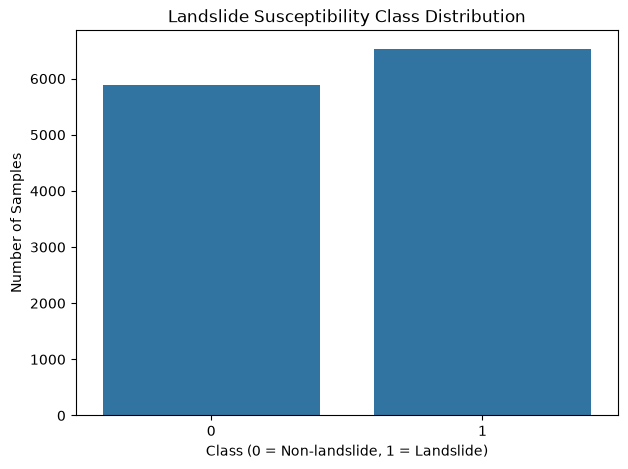

In [4]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="class")

plt.title("Landslide Susceptibility Class Distribution")
plt.xlabel("Class (0 = Non-landslide, 1 = Landslide)")
plt.ylabel("Number of Samples")

plt.show()


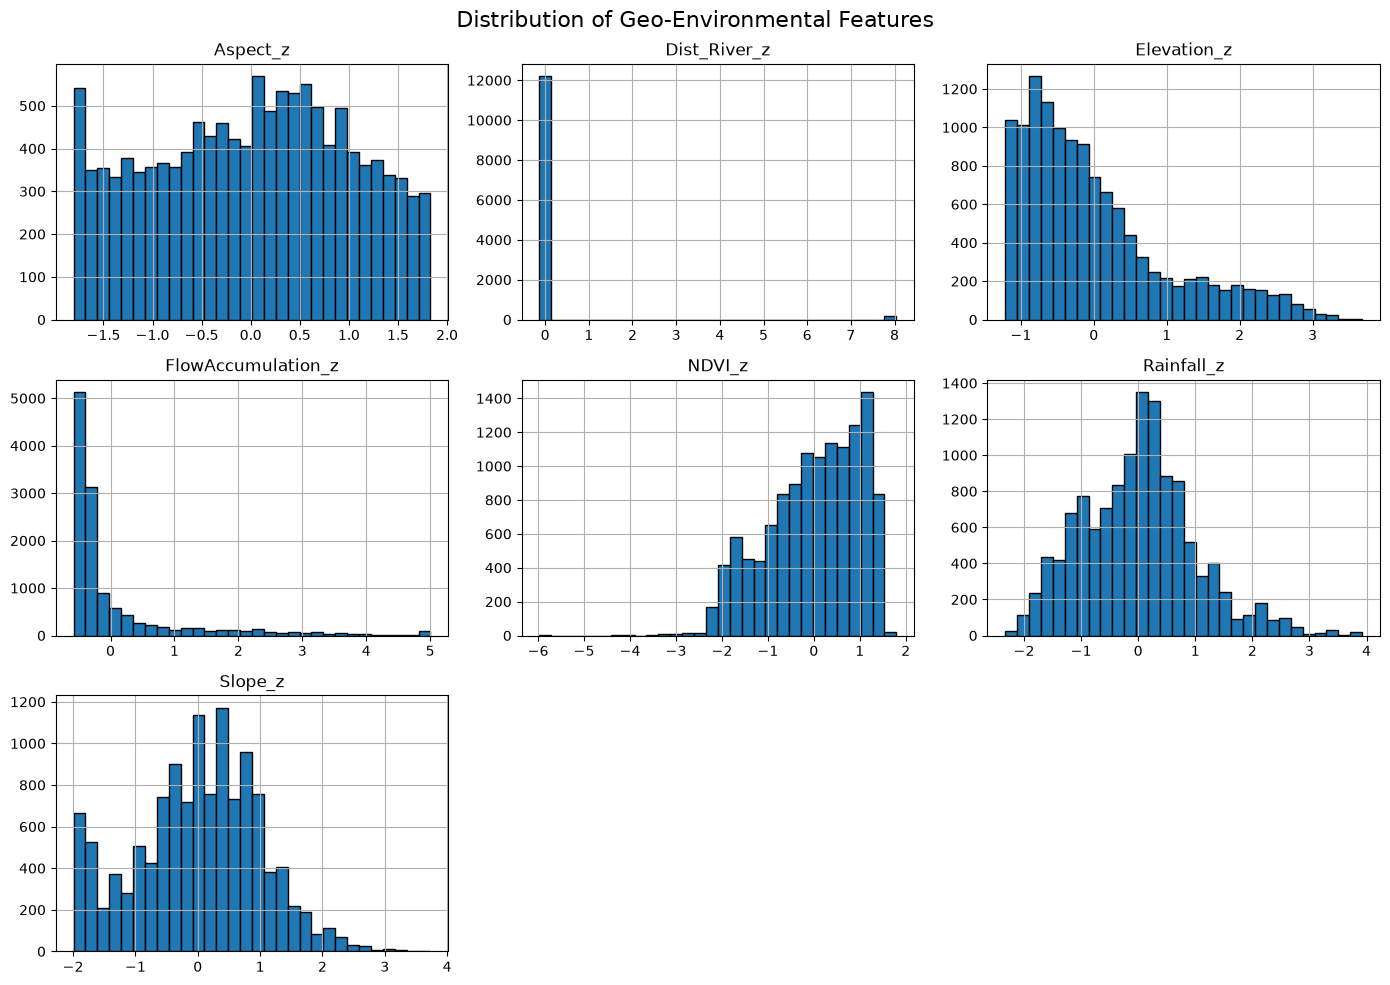

In [5]:

environmental_features = [
    "Aspect_z",
    "Dist_River_z",
    "Elevation_z",
    "FlowAccumulation_z",
    "NDVI_z",
    "Rainfall_z",
    "Slope_z"
]

df[environmental_features].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Geo-Environmental Features", fontsize=16)

plt.tight_layout()
plt.show()


In [23]:

print("Environmental Feature Statistics by Class:")

display(df.groupby("class")[environmental_features].mean())


Environmental Feature Statistics by Class:


,Aspect_z,Dist_River_z,Elevation_z,FlowAccumulation_z,NDVI_z,Rainfall_z,Slope_z
class,,,,,,,
0,-0.011389,0.129091,0.306399,-0.139862,-0.056858,-0.341412,-0.257822
1,0.010251,-0.116184,-0.275764,0.125878,0.051173,0.307276,0.232044


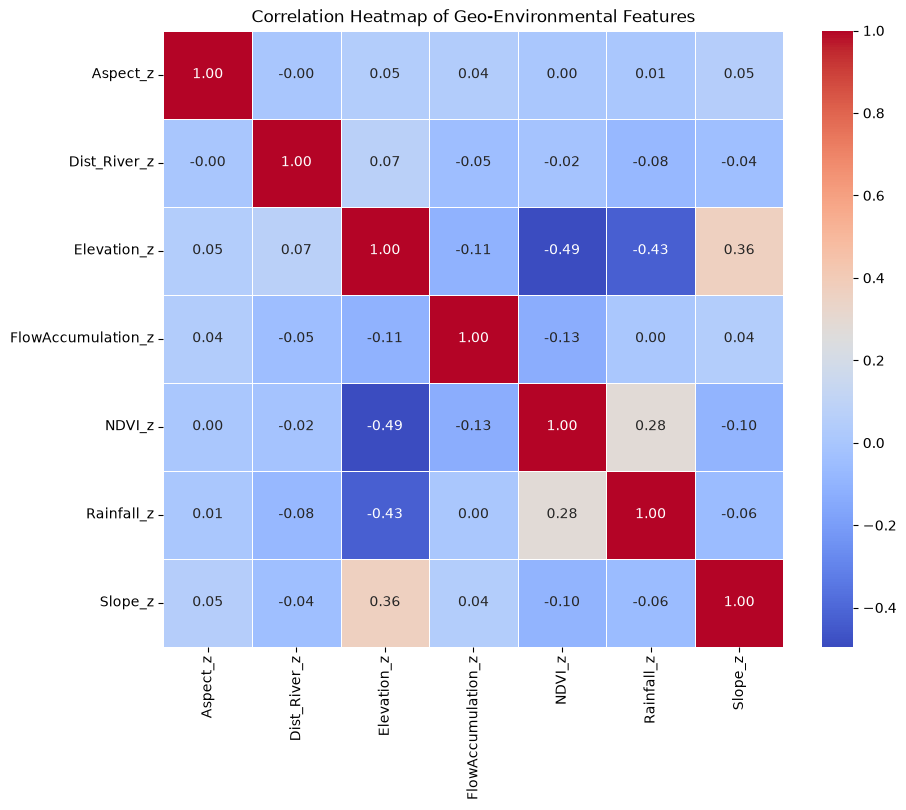

In [ ]:

correlation_matrix = df[environmental_features].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Geo-Environmental Features")
plt.show()


In [9]:

print("Distance from river statistics:")
display(df["Dist_River_z"].describe())

print("\nMost frequent values:")
display(df["Dist_River_z"].value_counts().head(10))

print("\nExtreme values by class:")
display(
    df.groupby("class")["Dist_River_z"]
      .agg(["min", "max", "mean", "median"])
)


Distance from river statistics:


count    1.240900e+04
mean     5.496986e-17
std      1.000040e+00
min     -1.314313e-01
25%     -1.293152e-01
50%     -1.263172e-01
75%     -1.208622e-01
max      8.040725e+00
Name: Dist_River_z, dtype: float64


Most frequent values:


Dist_River_z
-0.130550    245
-0.131255    243
 8.040725    189
-0.131431    179
-0.131079    138
-0.131037    134
-0.130726    116
-0.130021    115
-0.130197    109
-0.131182    104
Name: count, dtype: int64


Extreme values by class:


,min,max,mean,median
class,,,,
0,-0.131431,8.040725,0.129091,-0.125320
1,-0.131431,8.040725,-0.116184,-0.127314


In [ ]:

river_outliers = df[df["Dist_River_z"] > 1].copy()

print("Number of unusual records:", len(river_outliers))

print("\nClass distribution of unusual records:")
print(river_outliers["class"].value_counts())

print("\nSample records:")
display(
    river_outliers[
        ["class", "Dist_River_z", "longitude",
         "latitude", "n_samples_at_coord"]
    ].head(15)
)


Number of unusual records: 189

Class distribution of unusual records:
class
0    182
1      7
Name: count, dtype: int64

Sample records:


,class,Dist_River_z,longitude,latitude,n_samples_at_coord
8,0,8.040725,76.125224,30.976515,1
32,0,8.040725,76.068361,31.083505,1
94,0,8.040725,76.409002,30.670639,1
137,0,8.040725,76.582287,31.040924,1
138,0,8.040725,77.924640,29.978307,1
141,0,8.040725,77.495874,30.116019,1
154,0,8.040725,76.517878,31.009124,1
162,0,8.040725,77.443592,30.161564,1
163,0,8.040725,76.596570,31.037421,1
167,0,8.040725,77.240662,30.201718,1


In [ ]:


lulc_features = [
    "LULC_10", "LULC_20", "LULC_30",
    "LULC_40", "LULC_50", "LULC_60",
    "LULC_70", "LULC_80", "LULC_90",
    "LULC_100"
]

print("Land-cover feature counts:")

display(df[lulc_features].sum().sort_values(ascending=False))

print("\nUnique values in land-cover columns:")

for col in lulc_features:
    print(col, ":", sorted(df[col].unique()))


Land-cover feature counts:


LULC_10     6252
LULC_30     2495
LULC_60     1761
LULC_40      699
LULC_50      580
LULC_100     237
LULC_20      196
LULC_70      110
LULC_80       78
LULC_90        1
dtype: int64


Unique values in land-cover columns:
LULC_10 : [np.int64(0), np.int64(1)]
LULC_20 : [np.int64(0), np.int64(1)]
LULC_30 : [np.int64(0), np.int64(1)]
LULC_40 : [np.int64(0), np.int64(1)]
LULC_50 : [np.int64(0), np.int64(1)]
LULC_60 : [np.int64(0), np.int64(1)]
LULC_70 : [np.int64(0), np.int64(1)]
LULC_80 : [np.int64(0), np.int64(1)]
LULC_90 : [np.int64(0), np.int64(1)]
LULC_100 : [np.int64(0), np.int64(1)]


In [ ]:

feature_columns = [
    "Aspect_z",
    "Dist_River_z",
    "Elevation_z",
    "FlowAccumulation_z",
    "NDVI_z",
    "Rainfall_z",
    "Slope_z",
    "LULC_10",
    "LULC_20",
    "LULC_30",
    "LULC_40",
    "LULC_50",
    "LULC_60",
    "LULC_70",
    "LULC_80",
    "LULC_90",
    "LULC_100"
]

x = df[feature_columns]

y = df["class"]

print("Feature matrix shape:", x.shape)
print("Target shape:", y.shape)

print("\nSelected features:")
print(feature_columns)

print("\nTarget distribution:")
print(y.value_counts())


Feature matrix shape: (12409, 17)
Target shape: (12409,)

Selected features:
['Aspect_z', 'Dist_River_z', 'Elevation_z', 'FlowAccumulation_z', 'NDVI_z', 'Rainfall_z', 'Slope_z', 'LULC_10', 'LULC_20', 'LULC_30', 'LULC_40', 'LULC_50', 'LULC_60', 'LULC_70', 'LULC_80', 'LULC_90', 'LULC_100']

Target distribution:
class
1    6531
0    5878
Name: count, dtype: int64


In [13]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf = RandomForestClassifier(random_state=42)

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt']
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=2
)

grid_search.fit(x_train, y_train)

model = grid_search.best_estimator_

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV Score:")
print(grid_search.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}

Best CV Score:
0.8522967469876969


In [15]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

y_pred = model.predict(x_test)
y_prob = model.predict_proba(x_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nROC-AUC:", roc_auc_score(y_test, y_prob))

print("PR-AUC:", average_precision_score(y_test, y_prob))

Accuracy: 0.8432715551974215

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.78      0.83      1176
           1       0.82      0.90      0.86      1306

    accuracy                           0.84      2482
   macro avg       0.85      0.84      0.84      2482
weighted avg       0.85      0.84      0.84      2482


Confusion Matrix:
[[ 919  257]
 [ 132 1174]]

ROC-AUC: 0.9218813482513986
PR-AUC: 0.922969207965521


               Feature  Importance
2          Elevation_z    0.252507
6              Slope_z    0.172742
4               NDVI_z    0.155953
5           Rainfall_z    0.149976
1         Dist_River_z    0.084645
0             Aspect_z    0.069918
3   FlowAccumulation_z    0.047407
10             LULC_40    0.023102
7              LULC_10    0.010327
12             LULC_60    0.009531
11             LULC_50    0.009425
9              LULC_30    0.008793
16            LULC_100    0.003243
8              LULC_20    0.001171
13             LULC_70    0.000725
14             LULC_80    0.000511
15             LULC_90    0.000023


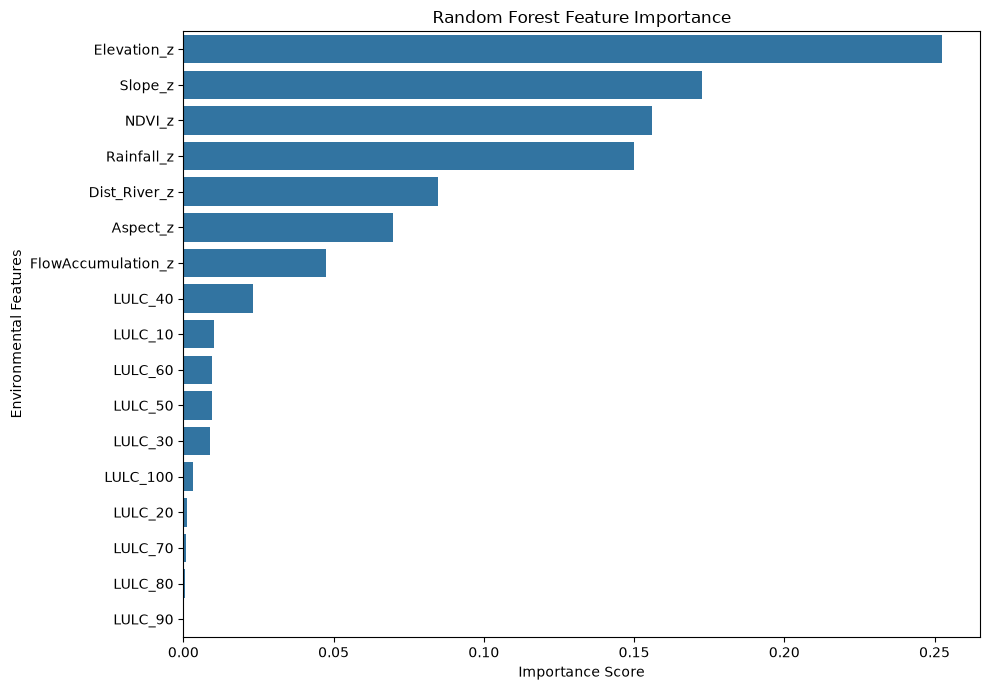

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

importance = pd.DataFrame({
    'Feature': x.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Environmental Features")
plt.tight_layout()
plt.show()


               Feature  Importance
2          Elevation_z    0.165335
5           Rainfall_z    0.090176
6              Slope_z    0.088644
4               NDVI_z    0.054137
1         Dist_River_z    0.021635
0             Aspect_z    0.006578
12             LULC_60    0.004712
11             LULC_50    0.003578
3   FlowAccumulation_z    0.003298
7              LULC_10    0.002768
10             LULC_40    0.002165
9              LULC_30    0.000450
13             LULC_70    0.000282
16            LULC_100    0.000063
14             LULC_80    0.000031
15             LULC_90    0.000000
8              LULC_20   -0.000042


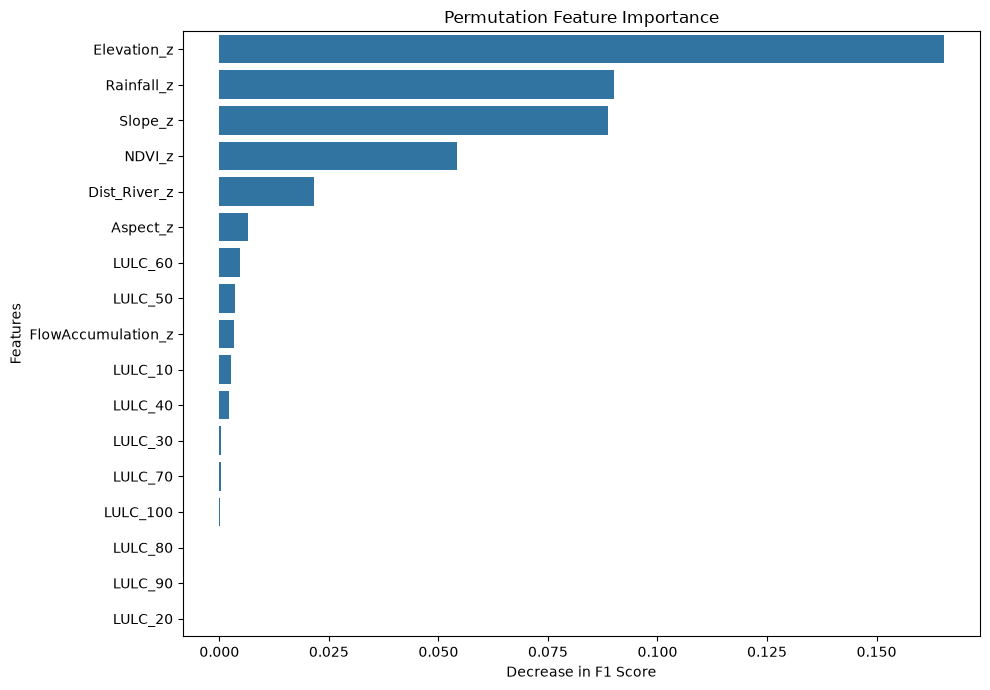

In [ ]:

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

perm_result = permutation_importance(
    model,
    x_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='f1',
    n_jobs=-1
)

perm_importance = pd.DataFrame({
    'Feature': x_test.columns,
    'Importance': perm_result.importances_mean
})

perm_importance = perm_importance.sort_values(
    by='Importance',
    ascending=False
)

print(perm_importance)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=perm_importance,
    x='Importance',
    y='Feature'
)

plt.title("Permutation Feature Importance")
plt.xlabel("Decrease in F1 Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


In [ ]:

import shap

explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(x_test)


c:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


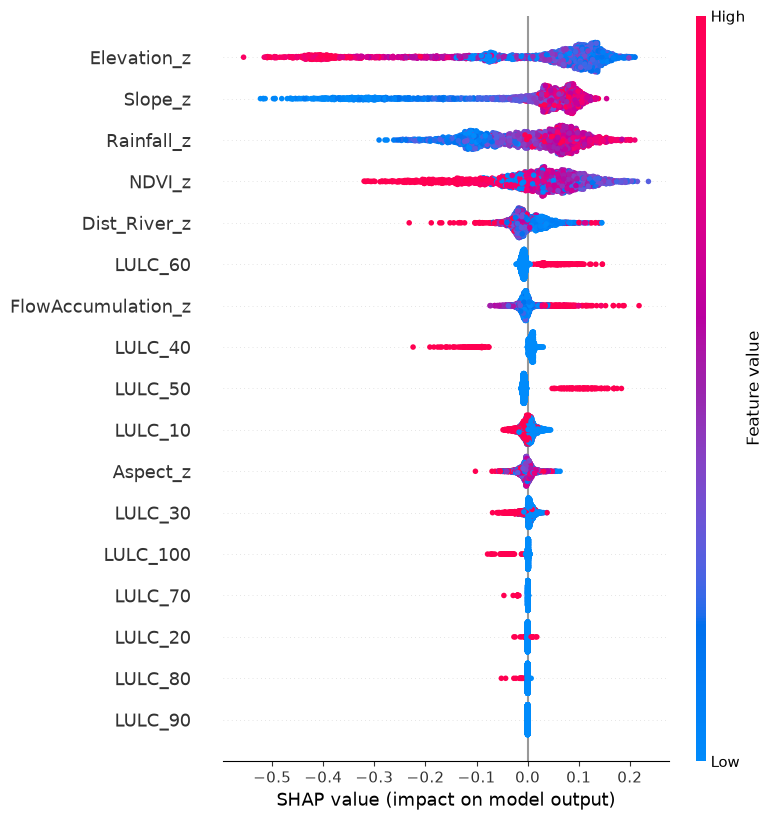

In [ ]:

shap_values_landslide = shap_values[:, :, 1]

shap.summary_plot(
    shap_values_landslide,
    x_test,
    feature_names=x_test.columns
)


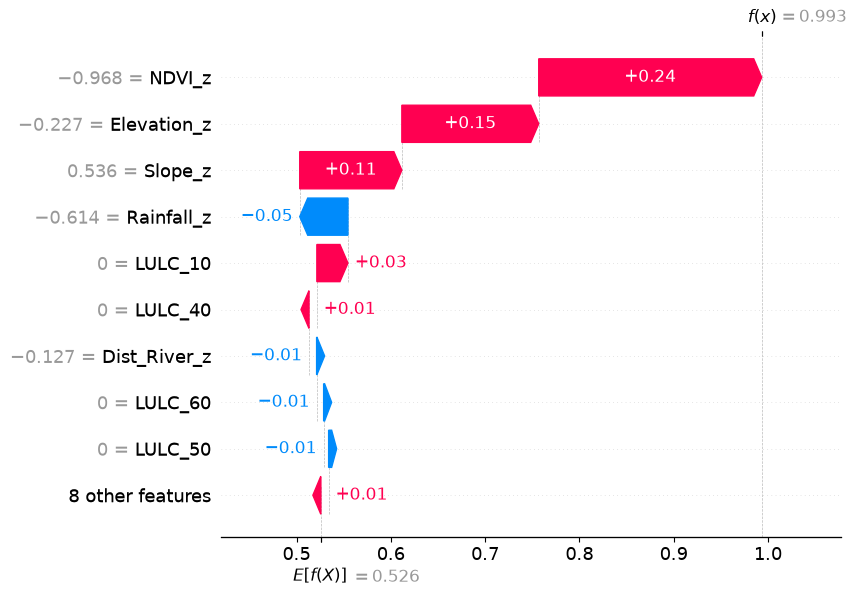

In [ ]:

sample_index = 0

explanation = shap.Explanation(
    values=shap_values_landslide[sample_index],
    base_values=explainer.expected_value[1],
    data=x_test.iloc[sample_index].values,
    feature_names=x_test.columns.tolist()
)

shap.plots.waterfall(explanation)


In [ ]:
import joblib

joblib.dump(model, "model.pkl")

feature_columns = x.columns.tolist()

joblib.dump(feature_columns, "feature_columns.pkl")

print("Model and feature columns saved successfully!")

Model and feature columns saved successfully!
